## Import Libraries and Data Loading

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [2]:
# Set the max display range
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 120)

In [3]:
df = pd.read_csv('bank_marketing_training.csv')

## Data Audit

In [4]:
# Inspect column nams and data types (dtypes)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26874 entries, 0 to 26873
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  26874 non-null  int64  
 1   job                  26874 non-null  str    
 2   marital              26874 non-null  str    
 3   education            26874 non-null  str    
 4   default              26874 non-null  str    
 5   housing              26874 non-null  str    
 6   loan                 26874 non-null  str    
 7   contact              26874 non-null  str    
 8   month                26874 non-null  str    
 9   day_of_week          26874 non-null  str    
 10  duration             26874 non-null  int64  
 11  campaign             26874 non-null  int64  
 12  days_since_previous  26874 non-null  int64  
 13  previous             26874 non-null  int64  
 14  previous_outcome     26874 non-null  str    
 15  emp.var.rate         26874 non-null  float64
 1

In [5]:
# Quick summary of numerical columns
df.describe()

,age,duration,campaign,days_since_previous,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000,26874.000000
mean,39.987758,257.741907,2.563035,962.714631,0.171058,0.086552,93.575794,-40.481670,3.627879,5167.103446
std,10.400285,258.977140,2.748746,186.324546,0.487657,1.569716,0.578933,4.626506,1.731948,72.080534
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.000000
25%,32.000000,103.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.000000
50%,38.000000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.000000
max,91.000000,4918.000000,43.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.000000


In [6]:
# Separate numerical and categorical columns
cat_cols = df.select_dtypes(include=['str']).columns.tolist()
num_cols = df.select_dtypes(include=['number']).columns.tolist()

In [7]:
# Inspect categorical and numerical distribution
print(f"There are {len(cat_cols)} categorical columns, which are:\n", cat_cols)
print(f"There are {len(num_cols)} numerical columns, which are:\n", num_cols)

There are 11 categorical columns, which are:
 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'previous_outcome', 'response']
There are 10 numerical columns, which are:
 ['age', 'duration', 'campaign', 'days_since_previous', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [8]:
# Check missing values
df.isnull().sum().sort_values(ascending=False)

age                    0
job                    0
marital                0
education              0
default                0
housing                0
loan                   0
contact                0
month                  0
day_of_week            0
duration               0
campaign               0
days_since_previous    0
previous               0
previous_outcome       0
emp.var.rate           0
cons.price.idx         0
cons.conf.idx          0
euribor3m              0
nr.employed            0
response               0
dtype: int64

## Basic Data Cleaning

In [9]:
# Drop duplicate rows
df = df.drop_duplicates()

In [10]:
# Trim whitespace in categorical columns
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

In [11]:
# Standardize category case
for col in cat_cols:
    df[col] = df[col].str.lower()

In [12]:
# Detect outliers in numerical columns
iqr_mult = 1.5
print("Number of outliers")
for col in num_cols:
    if col in df.columns:
        q1, q3 = df[col].quantile([0.25,0.75])
        iqr = q3 - q1
        lower, upper = q1 - iqr * iqr_mult, q3 + iqr * iqr_mult
        outliers = len(df[(df[col]<lower) | (df[col]>upper)])
        print(f"{col}: {outliers}")

Number of outliers
age: 299
duration: 1898
campaign: 1578
days_since_previous: 982
previous: 3664
emp.var.rate: 0
cons.price.idx: 0
cons.conf.idx: 287
euribor3m: 0
nr.employed: 0


## Define Target and Features

In [13]:
# Choose target variable
target_col = 'marital'
assert target_col in df.columns, "Update target_col to match the dataset."

# Sample class balance
if target_col in df.columns:
    print(df[target_col].value_counts(normalize=True))

marital
married     0.602307
single      0.281876
divorced    0.113696
unknown     0.002121
Name: proportion, dtype: float64


In [14]:
# Store the target and features
X = df.drop(columns=[target_col])
y = df[target_col]

In [15]:
X.head()

,age,job,education,default,housing,loan,contact,month,day_of_week,duration,campaign,days_since_previous,previous,previous_outcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,response
0,56,housemaid,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
1,57,services,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
2,41,blue-collar,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
3,25,services,high.school,no,yes,no,telephone,may,mon,222,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no
4,29,blue-collar,high.school,no,no,yes,telephone,may,mon,137,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191,no


In [16]:
y.head()

0    married
1    married
2    married
3     single
4     single
Name: marital, dtype: str

## Encode and Impute via Pipelines

In [17]:
# Create Pipelines for each data type
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Redefine cols to remove the target variable
cat_cols = [col for col in cat_cols if col != target_col]
num_cols = [col for col in num_cols if col != target_col]

# Design the master pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ],
    remainder='drop'
)

# Fit and transform
X_processed = preprocessor.fit_transform(X)

In [18]:
# Get feature names after one-hot encoding
cat_feature_names = preprocessor.named_transformers_['cat']['onehot'].get_feature_names_out(cat_cols)
feature_names = num_cols + cat_feature_names.tolist()

In [19]:
# Convert the transformed columns into a dataframe
X_processed = pd.DataFrame(X_processed, columns=feature_names)
X_processed.head()

,age,duration,campaign,days_since_previous,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_no,default_unknown,default_yes,housing_no,housing_unknown,housing_yes,loan_no,loan_unknown,loan_yes,contact_cellular,contact_telephone,month_apr,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,previous_outcome_failure,previous_outcome_nonexistent,previous_outcome_success,response_no,response_yes
0,1.539496,0.012529,-0.568645,0.194761,-0.35081,0.645569,0.722295,0.882122,0.709633,0.331499,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1.635647,-0.419927,-0.568645,0.194761,-0.35081,0.645569,0.722295,0.882122,0.709633,0.331499,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.097235,-0.157365,-0.568645,0.194761,-0.35081,0.645569,0.722295,0.882122,0.709633,0.331499,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,-1.441177,-0.138058,-0.568645,0.194761,-0.35081,0.645569,0.722295,0.882122,0.709633,0.331499,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,-1.056574,-0.466261,-0.568645,0.194761,-0.35081,0.645569,0.722295,0.882122,0.709633,0.331499,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## Train-Test Split

In [20]:
# Split the dataset to train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, 
    test_size=0.2, random_state=42, 
    stratify=y if y.nunique() <= 20 else None # Stratify to ensure proper distribution of categories
)

X_train.shape, X_test.shape

((21496, 61), (5374, 61))

## Exploratory Checks

In [21]:
# Class balance in train/test
print('Train class distribution')
display(X_train.value_counts(normalize=True))

print('\nTest class distribution')
display(X_test.value_counts(normalize=True))

Train class distribution


age        duration   campaign   days_since_previous  previous   emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  job_admin.  job_blue-collar  job_entrepreneur  job_housemaid  job_management  job_retired  job_self-employed  job_services  job_student  job_technician  job_unemployed  job_unknown  education_basic.4y  education_basic.6y  education_basic.9y  education_high.school  education_illiterate  education_professional.course  education_university.degree  education_unknown  default_no  default_unknown  default_yes  housing_no  housing_unknown  housing_yes  loan_no  loan_unknown  loan_yes  contact_cellular  contact_telephone  month_apr  month_aug  month_dec  month_jul  month_jun  month_mar  month_may  month_nov  month_oct  month_sep  day_of_week_fri  day_of_week_mon  day_of_week_thu  day_of_week_tue  day_of_week_wed  previous_outcome_failure  previous_outcome_nonexistent  previous_outcome_success  response_no  response_yes
-1.825780  -0.470123  -0.204856   0.194761 


Test class distribution


age        duration   campaign   days_since_previous  previous   emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  job_admin.  job_blue-collar  job_entrepreneur  job_housemaid  job_management  job_retired  job_self-employed  job_services  job_student  job_technician  job_unemployed  job_unknown  education_basic.4y  education_basic.6y  education_basic.9y  education_high.school  education_illiterate  education_professional.course  education_university.degree  education_unknown  default_no  default_unknown  default_yes  housing_no  housing_unknown  housing_yes  loan_no  loan_unknown  loan_yes  contact_cellular  contact_telephone  month_apr  month_aug  month_dec  month_jul  month_jun  month_mar  month_may  month_nov  month_oct  month_sep  day_of_week_fri  day_of_week_mon  day_of_week_thu  day_of_week_tue  day_of_week_wed  previous_outcome_failure  previous_outcome_nonexistent  previous_outcome_success  response_no  response_yes
 0.577989  -0.647738  -0.204856  0.194761  

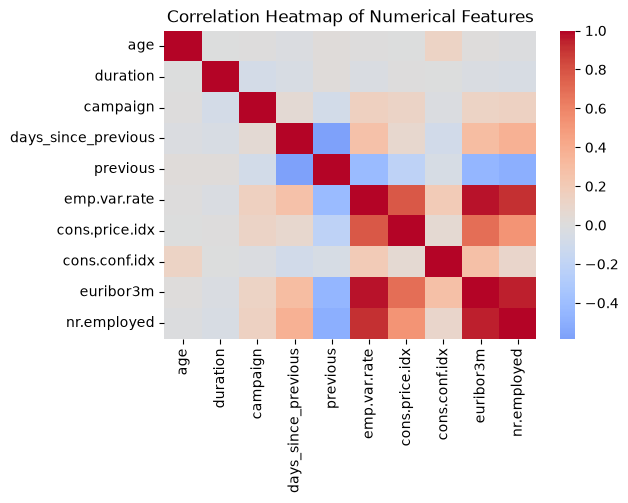

In [22]:
# Create a correlation heatmap for numerical columns
if len(num_cols) > 1:
    corr = pd.DataFrame(
        preprocessor.named_transformers_['num']['imputer'].transform(X[num_cols]), 
        columns=num_cols                                   # Get the imputed num cols
    ).corr()                                               # Get the correlation matrix

    plt.figure(figsize=(6,4))                              # Set the size of the figure
    sns.heatmap(corr, cmap='coolwarm', center=0)           # Create the heatmap using the correlation matrix
    plt.title('Correlation Heatmap of Numerical Features') # Set the title
    plt.show()

## Saved Processed Datasets and Artifacts

In [23]:
# Save CSVs
X_train.to_csv('X_train_processed.csv', index=False)
X_test.to_csv('X_test_processed.csv', index=False)
y_train.to_csv('y_train_processed.csv', index=False)
y_test.to_csv('y_test_processed.csv', index=False)

In [24]:
# Save preprocessors for reuse
import joblib
joblib.dump(preprocessor, 'preprocessor.joblib')

['preprocessor.joblib']